# Búsqueda de hiperparámetros y registro del modelo de propinas

Partimos del dataset que dejó el DAG `process_etl_taxi_data` en `s3://data/taxi/` y buscamos los
hiperparámetros del `HistGradientBoostingRegressor` (pérdida absoluta, como en AMq1) con Optuna.
Cada trial queda como un run anidado en MLflow. El mejor pipeline se reentrena con todo el train,
se evalúa en test y se registra como `taxi_tip_model`.

Lo que registramos es el pipeline entero, con el feature engineering adentro (ver
`src/taxi_tip/features.py`). Por eso la API y el DAG de lote solo tienen que pasarle las 11
columnas del ETL.

Antes de correrla:
1. Levantar los servicios: `docker compose --profile all up --build`.
2. Correr el DAG `process_etl_taxi_data` en Airflow.
3. Instalar el entorno con `uv sync` y elegir como kernel el `.venv` del repo.

In [1]:
import os

# Credenciales y endpoints de MinIO / MLflow vistos desde la máquina local
os.environ['AWS_ACCESS_KEY_ID'] = 'minio'
os.environ['AWS_SECRET_ACCESS_KEY'] = 'minio123'
os.environ['AWS_ENDPOINT_URL_S3'] = 'http://localhost:9000'
os.environ['MLFLOW_S3_ENDPOINT_URL'] = 'http://localhost:9000'

import datetime
import json
from pathlib import Path

import awswrangler as wr
import boto3
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold

import taxi_tip
from taxi_tip.features import RANDOM_STATE, RAW_FEATURES, TARGET, build_pipeline
from taxi_tip.mlflow_utils import (MODEL_NAME, get_or_create_experiment, load_champion,
                                   skops_trusted_types)

mlflow.set_tracking_uri('http://localhost:5001')
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 15

## Datos

Leemos el train y el test del último mes procesado por el ETL. Los parámetros del ETL (mes,
cantidad de filas) quedan en `data_info.json` y los registramos en el run.

In [2]:
train = wr.s3.read_parquet('s3://data/taxi/train.parquet')
test = wr.s3.read_parquet('s3://data/taxi/test.parquet')
data_info = json.loads(
    boto3.client('s3').get_object(Bucket='data', Key='taxi/data_info.json')['Body'].read()
)

# El ETL guarda enteros nullable; el modelo trabaja en float
X_train, y_train = train[RAW_FEATURES].astype('float64'), train[TARGET]
X_test, y_test_raw = test[RAW_FEATURES].astype('float64'), test[TARGET]

print(f"Mes: {data_info['month']} | train {X_train.shape} | test {X_test.shape}")
X_train.head()

Mes: 2026-03 | train (240000, 11) | test (60000, 11)


,trip_distance,duration_min,fare_amount,recargos,PULocationID,DOLocationID,passenger_count,hour,dow,RatecodeID,VendorID
0,8.74,33.866667,39.4,12.21,70.0,164.0,1.0,7.0,2.0,1.0,2.0
1,22.60,75.250000,70.0,23.96,132.0,125.0,1.0,16.0,4.0,2.0,1.0
2,1.70,14.550000,14.2,8.00,164.0,229.0,2.0,10.0,0.0,1.0,1.0
3,9.28,17.716667,87.0,1.00,196.0,132.0,1.0,6.0,4.0,5.0,2.0
4,1.38,14.933333,13.5,5.75,249.0,107.0,1.0,21.0,5.0,1.0,2.0


### Recorte del target

Igual que en AMq1, recortamos la cola superior extrema de la propina (errores tipo USD 397) en el
p99,5 del train. Evaluamos contra el test recortado y también contra el valor original.

In [3]:
tip_cap = float(y_train.quantile(0.995))
y_train = y_train.clip(lower=0, upper=tip_cap)
y_test = y_test_raw.clip(lower=0, upper=tip_cap)
print(f'Target recortado a [0, {tip_cap:.2f}] USD')

Target recortado a [0, 21.63] USD


## Baselines

Antes de buscar hiperparámetros, dos referencias simples:

- **Mediana**: siempre predice la mediana del train (el óptimo constante para MAE).
- **% del monto**: la propina típica es un porcentaje de lo que el pasajero ve en la terminal
  (`fare_amount + recargos`). Usamos el porcentaje mediano del train entre los viajes con
  propina; con tarifa 99 (desconocida) predice 0.

In [4]:
def metrics(y_true, y_pred) -> dict:
    """MAE, RMSE y R2 de una predicción."""
    return {'mae': mean_absolute_error(y_true, y_pred),
            'rmse': root_mean_squared_error(y_true, y_pred),
            'r2': r2_score(y_true, y_pred)}


baseline_median = DummyRegressor(strategy='median').fit(X_train, y_train).predict(X_test)

amount_train = X_train['fare_amount'] + X_train['recargos']
amount_test = X_test['fare_amount'] + X_test['recargos']
with_tip = y_train > 0
tip_pct = float(np.median(y_train[with_tip] / amount_train[with_tip]))
baseline_pct = np.where(X_test['RatecodeID'] == 99, 0.0, tip_pct * amount_test)

baselines = {'mediana': metrics(y_test, baseline_median),
             'pct_monto': metrics(y_test, baseline_pct)}
print(f'Porcentaje mediano de propina: {100 * tip_pct:.2f} %')
pd.DataFrame(baselines).T.round(4)

Porcentaje mediano de propina: 20.00 %


,mae,rmse,r2
mediana,2.3237,3.8822,-0.0597
pct_monto,1.1116,2.5370,0.5474


## Búsqueda de hiperparámetros

Usamos el mismo espacio de búsqueda que en AMq1. Cada trial evalúa el pipeline completo con
validación cruzada de 3 folds sobre el train (sin tocar el test) y se registra como run hijo del
run padre. Con el `MedianPruner`, si después de dos folds un trial viene peor que la mediana de los
anteriores, se corta.

In [5]:
experiment_id = get_or_create_experiment('Taxi Tip')
run_name = 'optuna_hgb_' + datetime.datetime.now().strftime('%Y-%m-%d_%H-%M')


def objective(trial: optuna.Trial) -> float:
    """
    Entrena el pipeline con los hiperparámetros del trial y devuelve el MAE medio de la CV.

    :param trial: Trial de Optuna.
    :return: MAE de validación cruzada (USD).
    """
    params = dict(
        max_depth=trial.suggest_int('max_depth', 4, 8),
        learning_rate=trial.suggest_float('learning_rate', 0.03, 0.30, log=True),
        max_iter=trial.suggest_int('max_iter', 100, 200, step=50),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 10, 200, log=True),
        l2_regularization=trial.suggest_float('l2_regularization', 1e-3, 10.0, log=True),
        max_leaf_nodes=trial.suggest_int('max_leaf_nodes', 15, 40),
    )
    with mlflow.start_run(experiment_id=experiment_id, run_name=f'trial_{trial.number}',
                          nested=True):
        mlflow.log_params(params)
        folds = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
        maes = []
        for i, (idx_fit, idx_val) in enumerate(folds.split(X_train)):
            pipe = build_pipeline(**params)
            pipe.fit(X_train.iloc[idx_fit], y_train.iloc[idx_fit])
            maes.append(mean_absolute_error(y_train.iloc[idx_val],
                                            pipe.predict(X_train.iloc[idx_val])))
            trial.report(float(np.mean(maes)), i)
            if trial.should_prune():
                mlflow.set_tag('estado', 'podado')
                mlflow.log_metric('cv_mae', float(np.mean(maes)))
                raise optuna.TrialPruned()
        cv_mae = float(np.mean(maes))
        mlflow.set_tag('estado', 'completo')
        mlflow.log_metric('cv_mae', cv_mae)
    return cv_mae


with mlflow.start_run(experiment_id=experiment_id, run_name=run_name,
                      tags={'modelo': 'HistGradientBoostingRegressor', 'proyecto': 'taxi_tip'}
                      ) as parent_run:
    mlflow.log_params({'etl_month': data_info['month'], 'rows_train': len(X_train),
                       'rows_test': len(X_test), 'n_trials': N_TRIALS, 'tip_cap': tip_cap})
    for name, values in baselines.items():
        mlflow.log_metrics({f'baseline_{name}_{k}': v for k, v in values.items()})

    study = optuna.create_study(
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
    )
    study.optimize(objective, n_trials=N_TRIALS)

    mlflow.log_params({f'best_{k}': v for k, v in study.best_params.items()})
    mlflow.log_metric('best_cv_mae', study.best_value)

n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f'{N_TRIALS - n_pruned} trials completos, {n_pruned} podados')
print('Mejores hiperparámetros:', study.best_params)
print(f'MAE de CV: {study.best_value:.4f} USD')

🏃 View run trial_0 at: http://localhost:5001/#/experiments/2/runs/59b4b07d849a405989c41a7ca1079935
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_1 at: http://localhost:5001/#/experiments/2/runs/98079c25ebeb430ba65b2e059757e53b
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_2 at: http://localhost:5001/#/experiments/2/runs/f60225facb694748ac20f2163725ed33
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_3 at: http://localhost:5001/#/experiments/2/runs/f1ee65fd144442768931d0e2038a8248
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_4 at: http://localhost:5001/#/experiments/2/runs/47ec9ed0a4f2492f9699e1a50f0c4a03
🧪 View experiment at: http://localhost:5001/#/experiments/2


...

🏃 View run trial_10 at: http://localhost:5001/#/experiments/2/runs/a4ec350ff9a94931b871a1bb37a3b697
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_11 at: http://localhost:5001/#/experiments/2/runs/38585a481f5643f9bc9a4131c057e0a6
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_12 at: http://localhost:5001/#/experiments/2/runs/814973b976be4d54b353acf49613b66b
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_13 at: http://localhost:5001/#/experiments/2/runs/b57ea92ef3bb4d5d825c96db758e46eb
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_14 at: http://localhost:5001/#/experiments/2/runs/20c456b5b4fd47fbb85477325884661c
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run optuna_hgb_2026-10-12_11-46 at: http://localhost:5001/#/experiments/2/runs/4794be1f46fc4d79a4c5ec735d71c71d
🧪 View experiment at: http://localhost:5001/#/experiments/2
11 trials completos, 4 podados
Mejores hiperparámetros: {'max_depth': 7, 'learning_rate': 0.20907947751050307, 'max_iter': 200, 'min_samples_leaf': 42, 'l2_regularization': 0.0010262783264738974, 'max_leaf_nodes': 24}
MAE de CV: 1.0058 USD


## Modelo final

Reentrenamos el pipeline con los mejores hiperparámetros sobre todo el train y lo evaluamos en
test. Todo se registra en el mismo run padre.

In [6]:
final_model = build_pipeline(**study.best_params).fit(X_train, y_train)
y_pred = final_model.predict(X_test)

test_metrics = metrics(y_test, y_pred)
test_metrics_raw = metrics(y_test_raw, y_pred)

with mlflow.start_run(run_id=parent_run.info.run_id):
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
    mlflow.log_metrics({f'test_sin_recorte_{k}': v for k, v in test_metrics_raw.items()})

pd.DataFrame({**baselines, 'HistGB afinado': test_metrics}).T.round(4)

🏃 View run optuna_hgb_2026-10-12_11-46 at: http://localhost:5001/#/experiments/2/runs/4794be1f46fc4d79a4c5ec735d71c71d
🧪 View experiment at: http://localhost:5001/#/experiments/2


,mae,rmse,r2
mediana,2.3237,3.8822,-0.0597
pct_monto,1.1116,2.5370,0.5474
HistGB afinado,1.0154,2.2146,0.6552


### Gráficos

- Predicción vs. propina real sobre una muestra del test.
- Importancia por permutación de las 11 columnas de entrada (aumento del MAE al mezclar cada una).

🏃 View run optuna_hgb_2026-10-12_11-46 at: http://localhost:5001/#/experiments/2/runs/4794be1f46fc4d79a4c5ec735d71c71d
🧪 View experiment at: http://localhost:5001/#/experiments/2


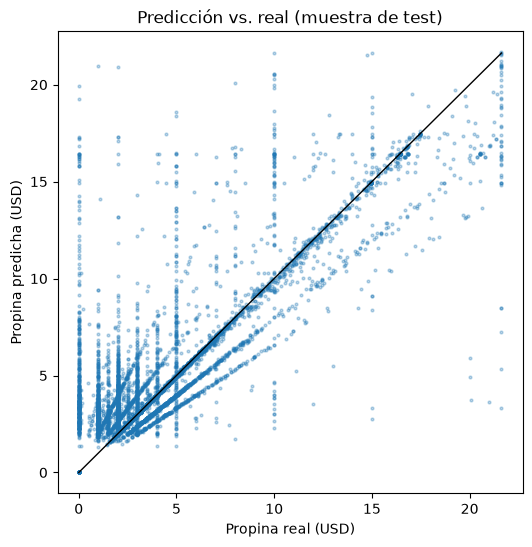

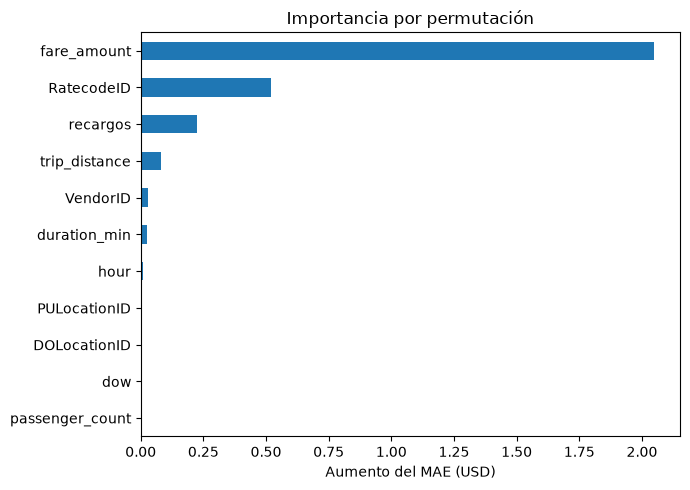

In [7]:
sample = X_test.sample(10_000, random_state=RANDOM_STATE)
y_sample = y_test.loc[sample.index]

fig_pred, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_sample, final_model.predict(sample), s=4, alpha=0.3)
ax.plot([0, tip_cap], [0, tip_cap], color='black', linewidth=1)
ax.set_xlabel('Propina real (USD)')
ax.set_ylabel('Propina predicha (USD)')
ax.set_title('Predicción vs. real (muestra de test)')

importance = permutation_importance(final_model, sample, y_sample,
                                    scoring='neg_mean_absolute_error', n_repeats=5,
                                    random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=RAW_FEATURES).sort_values()

fig_imp, ax = plt.subplots(figsize=(7, 5))
importance.plot.barh(ax=ax)
ax.set_xlabel('Aumento del MAE (USD)')
ax.set_title('Importancia por permutación')
fig_imp.tight_layout()

with mlflow.start_run(run_id=parent_run.info.run_id):
    mlflow.log_figure(fig_pred, 'prediccion_vs_real.png')
    mlflow.log_figure(fig_imp, 'importancia_permutacion.png')

### Guardado del modelo

Para loguear el pipeline le pasamos a MLflow `code_paths` con la carpeta de `taxi_tip`: así el
código del transformer queda dentro del artefacto y la API y Airflow lo pueden cargar sin instalar
nada. También hay que pasarle `skops_trusted_types`, porque MLflow 3 guarda con skops y skops no
carga clases que no conoce. La firma y el `input_example` salen de las 11 columnas del ETL.

In [8]:
signature = infer_signature(X_train, final_model.predict(X_train.head(100)))

with mlflow.start_run(run_id=parent_run.info.run_id):
    model_info = mlflow.sklearn.log_model(
        final_model,
        name='model',
        signature=signature,
        input_example=X_train.head(3),
        code_paths=[str(Path(taxi_tip.__file__).parent)],
        skops_trusted_types=skops_trusted_types(final_model),
    )
print(model_info.model_uri)

2026/10/12 11:48:47 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run optuna_hgb_2026-10-12_11-46 at: http://localhost:5001/#/experiments/2/runs/4794be1f46fc4d79a4c5ec735d71c71d
🧪 View experiment at: http://localhost:5001/#/experiments/2
models:/m-09fdbbf18fb44ee6986597652e3d0e90


## Registro del modelo

Creamos una versión de `taxi_tip_model` y le guardamos como tags los hiperparámetros y el MAE de
test. Ese MAE lo calculamos contra la propina real, sin recortar, porque contra eso mide también la
predicción en lote.

Para decidir si pasa a `champion`, evaluamos al champion actual (si hay) con este mismo test: si
el modelo nuevo tiene menor MAE, pasa a `champion`; si no, queda como `challenger`.

In [9]:
client = MlflowClient()
try:
    client.get_registered_model(MODEL_NAME)
except mlflow.exceptions.MlflowException:
    client.create_registered_model(
        name=MODEL_NAME,
        description='Estima la propina (USD) de un viaje de Yellow Taxi NYC pagado con tarjeta.',
    )

tags = {**{k: str(v) for k, v in study.best_params.items()},
        'modelo': 'HistGradientBoostingRegressor', 'etl_month': data_info['month'],
        'mae_test': str(test_metrics_raw['mae'])}
version = client.create_model_version(name=MODEL_NAME, source=model_info.model_uri,
                                      run_id=parent_run.info.run_id, tags=tags,
                                      description=f'Optuna, {N_TRIALS} trials')

champion = load_champion()
if champion is None:
    client.set_registered_model_alias(MODEL_NAME, 'champion', version.version)
    print(f'No había champion: la versión {version.version} pasa a champion '
          f'(MAE {test_metrics_raw["mae"]:.4f})')
else:
    champion_version, champion_model = champion
    champion_mae = mean_absolute_error(y_test_raw, champion_model.predict(X_test))
    if test_metrics_raw['mae'] < champion_mae:
        client.set_registered_model_alias(MODEL_NAME, 'champion', version.version)
        print(f'Versión {version.version} es el nuevo champion: MAE {test_metrics_raw["mae"]:.4f} '
              f'vs {champion_mae:.4f} de la v{champion_version}')
    else:
        client.set_registered_model_alias(MODEL_NAME, 'challenger', version.version)
        print(f'Versión {version.version} queda como challenger: MAE {test_metrics_raw["mae"]:.4f} '
              f'vs {champion_mae:.4f} de la v{champion_version}')

2026/10/12 11:48:47 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: taxi_tip_model, version 1


No había champion: la versión 1 pasa a champion (MAE 1.0511)


## Prueba de carga

Cargamos el champion desde el registro, como lo va a hacer la API, y predecimos unos viajes del
test.

In [10]:
champion = mlflow.sklearn.load_model(f'models:/{MODEL_NAME}@champion')
check = X_test.head(5).copy()
check['propina_real'] = y_test_raw.head(5).values
check['propina_predicha'] = champion.predict(X_test.head(5)).round(2)
check

,trip_distance,duration_min,fare_amount,recargos,PULocationID,DOLocationID,passenger_count,hour,dow,RatecodeID,VendorID,propina_real,propina_predicha
0,0.78,6.416667,7.9,4.75,68.0,234.0,1.0,14.0,6.0,1.0,2.0,2.53,2.53
1,4.50,23.166667,24.7,5.75,231.0,142.0,1.0,1.0,6.0,1.0,2.0,2.00,6.08
2,0.35,1.516667,4.4,5.00,236.0,236.0,1.0,22.0,4.0,1.0,2.0,1.88,1.87
3,1.61,9.683333,12.1,4.75,229.0,233.0,2.0,11.0,1.0,1.0,2.0,3.37,3.37
4,0.78,5.333333,7.2,5.75,148.0,148.0,1.0,22.0,0.0,1.0,2.0,2.00,2.59
